# Welcome to a simple coding crash course! 

Author: Dario Cafasso \
Last update: 21/10/2026

In [1]:
import os
MYPATH = os.getcwd()
os.environ["MYPATH"] = MYPATH   # for shell use



---



# What is Linux?

Linux is the **kernel**--the fundamental software--at the heart of the **open-source** ecosystem. The **Operating System** (OS) called **Ubuntu** is a Linux distribution: a core program plus a curated set of tools and libraries, tested to work together, with an installer and usually a way to update it. Specifically, the Linux kernel plus GNU tools, a package manager, a desktop environment and applications.

The roots of computing trace back to machines like **ENIAC** in **1945**, which lacked an OS entirely and required engineers to physically rewire patch cables to execute programs. The first operating systems appeared in the **1950s** as **batch monitors**, which automatically loaded and ran programs from punch cards or tape. The true turning point arrived in the **1970s** with the **Unix** OS, developed at AT&T Bell Labs. Rewritten in C, Unix set the standard for multitasking and portability across different physical architectures, but its restrictive **proprietary license** prevented developers from modifying the source code to fix bugs or adapt drivers.

To combat these restrictions, Richard Stallman launched the **GNU Project** in **1983** to build a completely free OS, giving it a name based on the recursive acronym "GNU’s Not Unix." Stallman legally anchored this ethos through **copyleft licensing**--specifically the **GNU General Public License** (GPL)--ensuring derivative softwares remained free for everyone to use, study, and modify.

By the late **1980s**, GNU was building out its user environment, including **Bash** (Bourne Again SHell), written by Brian Fox in **1989** as a free command interpreter to replace the proprietary Bourne shell. By the early 1990s, GNU had nearly all the necessary utilities, but still lacked a functional kernel. Linus Torvalds supplied the final piece in **1991** by releasing the **Linux kernel**. Merging this kernel with GNU’s utilities yielded the complete operating systems that power servers and open-source infrastructure worldwide, while the kernel itself also laid the foundation for Android.

Each layer within this architecture plays a distinct role: the Linux kernel manages the underlying physical hardware, GNU tools provide the core system environment and utilities, and Bash serves as the command-line bridge connecting users directly to the entire software stack. Together, these Linux-based systems offer a free, open-source alternative to expensive, proprietary platforms like Windows and macOS.

Bash language
-----------------

Bash acts as a specialized **scripting language** that serves as software "glue" within the interactive **terminal shell**--the interface where users enter commands to trigger utilities and manage the system. It is called a shell because it forms the outer layer wrapping around the kernel to translate user input into system instructions. 

Each command runs as a process (opens a shell) with its own Process ID. Rather than compiling code into binary executable files like C, Bash reads plain-text scripts line-by-line, allowing users to pipe data between utilities and automate complex workflows directly inside the operating system.

**Basic commands**

- *pwd*  #Print Working Directory<br>
Example: pwd displays the current absolute path (e.g., /home/user/projects).

- *ls [options] [path]*  #List files and directories<br>
Example: ls lists visible files, ls -la lists all files including hidden ones with permissions and sizes.

- *cd [path]*  #Change Directory<br>
Example: cd ~ navigates to user, cd .. steps up one directory level, cd . stays in current directory.

- *echo "[text]"*  #Print text to standard output<br>
Example: echo "Build completed" prints Build completed to the screen.

- *sudo [command]*  #SuperUser Do (Execute command with root/administrative privileges)<br>
Example: sudo su gives admin privileges, sudo apt update updates system packages as root.

- *clear*  #Clear terminal screen<br>
Example: clear wipes previous commands and output from the terminal screen, resetting your prompt to the top.


- *exit*  #Terminate current sub-shell<br>
Example: terminate the root shell spawned by sudo su, or close the terminal shell.

**Processes and system**

- *ps aux*  #List all running processes<br>
Example: ps aux | grep python lists active processes and filters for those running Python.

- *kill [PID]*  #Terminate a process by Process ID<br>
Example: kill 1234 sends a termination signal to process 1234, kill -9 1234 force-kills a stuck process.

- *top*  #Display real-time processes and resource usage<br>
Example: top opens a live dashboard of CPU/RAM usage (press q to exit).

- *df -h*  #Show disk space of mounted filesystems<br>
Example: df -h displays total, used and available space in human-readable units (MB/GB).

- *du -sh [directory]*  #Show total size of a directory<br>
Example: du -sh my_data displays the summarized size of the my_data folder (e.g., 15M).

In Bash, the PID of the current shell is stored in the special variable `$$`:

In [2]:
!cd ~ && pwd && echo $$   # Process A starts, changes directory, and immediately dies.
!pwd && echo $$           # Process B starts in the original root folder, prints path, and dies.

/home/dario
63996
/home/dario/Projects/CollabCoding
63997


Memory dies with processes. To remember, run a single multi-line command

In [3]:
%%bash

cd ..          # Runs in Subshell Process A
pwd            # Runs in Subshell Process A (remains inside my_folder)
echo $$

/home/dario/Projects
63999


or save the path and use %cd to change working directory

In [4]:
%cd ..           
!ls         
%cd $MYPATH     

/home/dario/Projects
CollabCoding  EM-shower-simulator-with-NN  QSqueeG
/home/dario/Projects/CollabCoding


Practicing with scripts
-----------------------

A Bash script is a plain-text file of shell commands, usually starting with a shebang (`#!/bin/bash`), that Bash reads and executes line by line. It can use variables, loops and conditionals to automate tasks, and runs in a child shell when launched with `./script.sh`, or in the current shell when launched with `source`.

**File and directories**

- *touch [filename]*  #Create Empty File / Update Timestamp<br>
Example: touch notes.txt creates an empty file named notes.txt.

- *mkdir [directory_name]*  #Make Directory<br>
Example: mkdir scripts creates a new folder named scripts.

- *find [path] -name "[pattern]"*  #Find files and directories<br>
Example: find . -name "*.txt" searches the current folder and subfolders for all .txt files.

- *cp [source] [destination]*  #Copy files or directories<br>
Example: cp file.txt backup.txt copies a file, cp -r /source /backup/ recursively copies an entire folder.

- *mv [source] [destination]*  #Move or Rename files and directories<br>
Example: mv file1 ../Folder/file1 moves file1 up one level into Folder, mv old.txt new.txt renames old.txt.

- *rm [path]*  #Remove files or directories<br>
Example: rm file.txt deletes a file, rm -r folder/ recursively deletes a folder and its contents.

- *chmod [permissions] [filename]*  #Change file permissions<br>
Example: chmod +x build.sh makes a script executable, chmod 755 script.sh sets full owner and read/execute permissions.

- *./[executable]*  #Execute program or script in current directory<br>
Example: ./build.sh runs an executable script located in your current folder (. represents the current directory).

- *source [file]*  #Execute commands from a file in the current shell<br>
Example: source ~/.bashrc reloads your Bash configuration without restarting the terminal.

**Contents manipulation**

- *cat [filename]*  #Concatenate and display file content<br>
Example: cat config.txt outputs the full text contents of config.txt to the terminal screen.

- *grep "[pattern]" [filename]*  #Search text for a matching pattern<br>
Example: grep "ERROR" server.log finds lines with "ERROR", grep -i "error" server.log makes the search case-insensitive.

- *nano [filename]*  #Terminal Text Editor<br>
Example: nano script.sh opens script.sh in a lightweight, interactive text editor directly within the terminal window.

- *[command_1] | [command_2]*  #Pipe Operator (Pass output as input)<br>
Example: cat server.log | grep "500" reads server.log and passes the text into grep to filter for "500" error lines.

- *[command] > [file]*  #Overwrite Redirect (Save output to file)<br>
Example: ls -la > list.txt writes directory listing into list.txt, replacing any existing content.

- *[command] >> [file]*  #Append Redirect (Add output to file end)<br>
Example: echo "Done" >> log.txt appends "Done" to the end of log.txt without deleting existing text.

Let us now create and execute a simple script manipulating some files and their contents:

In [5]:
%%bash 

mkdir $MYPATH/TestScript
cd $MYPATH/TestScript

touch testscript.sh
ls

my_script='#!/bin/bash
echo "Linux Bash Scripting" > words.txt
echo "101 202 303" > numbers.txt
echo "Files created!"
variable="Now I remember!"'

echo "$my_script" > testscript.sh

mkdir: /home/dario/Projects/CollabCoding/TestScript: File exists


generate_ssh_key.py
numbers.txt
testscript.py
testscript.sh
text.json
text.txt
words.txt


In a notebook, this cell is equivalent to using the magic command `%%writefile`:

In [6]:
%%writefile $MYPATH/TestScript/testscript.sh
#!/bin/bash
echo "Linux Bash Scripting" > words.txt
echo "101 202 303" > numbers.txt
echo "Files created!"
variable="Now I remember!"

Overwriting /home/dario/Projects/CollabCoding/TestScript/testscript.sh


This script creates files filled with words and numbers, but it also creates a `variable`:

In [7]:
%cd $MYPATH/TestScript/
!chmod +x testscript.sh
!./testscript.sh && echo $variable

/home/dario/Projects/CollabCoding/TestScript
Files created!



However, the previous call does not remember the variable, while executing the script with source locates the variables within the current shell. \
We are able to read variable with 


In [8]:
%cd $MYPATH/TestScript/
!source testscript.sh && echo "Shell 1:" $variable
!echo "Shell 2:" $variable

/home/dario/Projects/CollabCoding/TestScript
Files created!
Shell 1: Now I remember!
Shell 2:


We also remember the variable `MYPATH` in the current shell because of a little trick with python at the beginning.

Imagine now we want to append some more complex instructions to ourscript. 
\
In particular, we want our script to:

- Loop through every item in the folder
- Make sure file's an actual file (not a subdirectory)
- Check if the word "Bash" is inside the file

In [9]:
%%bash 

cd $MYPATH/TestScript

my_script_app='
echo -e "--------------------"
for file in ./*.txt; do
  if [ -f  "$file" ]; then
    if grep -q "Bash" "$file"; then
      echo "Word found in $file"
      cat "$file"
    else
      echo "Word NOT found in $file"
    fi
    echo "--------------------"
  fi
done
echo -e "Script executed!"'

echo "$my_script_app" >> testscript.sh

We appended the new part of the script to the already existing file. \
The output is:

In [10]:
! $MYPATH/TestScript/testscript.sh

Files created!
--------------------
Word NOT found in ./numbers.txt
--------------------
Word NOT found in ./text.txt
--------------------
Word found in ./words.txt
Linux Bash Scripting
--------------------
Script executed!


Practicing environments
-----------------------

An **environment** is the set of variables, paths and installed software that a process sees. 
Each process inherits a copy of its parent's environment, but changes made by a child never propagate back to the parent. 

We already saw this with the variable `variable`, which we could only read after running the script in the same shell. Python packages also live in an environment, and the environment of this notebook is determined by its kernel. 

To check your current environment using the path of your packages:
- *which [command]*  #Display the full path of a command's executable<br>
Example: which python shows the path of the active Python binary (e.g., /usr/bin/python).

In [11]:
!which python

/home/dario/Applications/anaconda3/bin/python


The Python distribution **Anaconda** bundles Python with a wide range of scientific libraries, and its package manager, **conda**, lets you create and manage separate environments, so that different projects can use different package versions. 

**Conda environments**

- *conda list*  #List packages installed in the active environment<br>
Example: conda list outputs all installed libraries with their exact versions.

- *conda create -n [name]*  #Create a new Conda environment<br>
Example: conda create -n dev_env python=3.10 creates dev_env with Python 3.10.

- *conda activate [env_name]*  #Activate a Conda environment<br>
Example: conda activate my_env switches your terminal into the isolated my_env environment.

- *conda deactivate*  #Leave the active environment and return to the previous one (base)<br>
Example: conda deactivate switches your terminal back to the base environment.

- *conda remove -n [env_name] --all*  #Delete a Conda environment and all its packages<br>
Example: conda remove -n dev_env --all permanently deletes dev_env. Deactivate it first.


To check the active environments run:

In [12]:
#!conda info --envs

Note that you can’t remove the environment you are currently in, so run conda deactivate first. 

As with activate, these commands don’t work with ! in a notebook, because each ! line is a temporary subshell.

To install packages in the chosen environment you can run:

In [13]:
#!conda install git
!which git

/home/dario/Applications/anaconda3/bin/git


As we shall see, the git package is crucial for version control!

Version control with Git
------------------------

A **Version Control System** (VCS) records the changes made to a set of files over time, so you can see who changed what and when, compare versions, and go back to any earlier state.

To manage the Linux kernel's development, Linus Torvalds created **Git** in **2005**. This is a **distributed** VCS: every user holds a full copy of the project and its history, so most operations work offline. It is used together with a hosting platform such as **GitHub** to collaborate.

Key concepts:

- **Repository** (repo): the project folder plus its full history (stored in the hidden `.git` folder).
- **Commit**: a saved snapshot of the project, with a message describing the change.
- **Branch**: an independent line of development, e.g. to try a new feature without touching the main code.
- **Remote**: a copy of the repository on a server (e.g. GitHub), usually called `origin`.

A file goes through three areas: working directory (edited) → staging area (`git add`) → repository (`git commit`).

**Basic commands**

- *git config --global user.name "[name]"*  #Set your identity (once)<br>
Example: git config --global user.email "me@mail.com" sets the email attached to your commits.

- *git init*  #Create a new repository in the current folder<br>
Example: git init turns the current folder into a Git repository.

- *git status*  #Show modified, staged and untracked files<br>
Example: git status tells you what is ready to be committed.

- *git add [file]*  #Add changes to the staging area<br>
Example: git add script.py stages one file, git add . stages everything.

- *git commit -m "[message]"*  #Save the staged changes as a commit<br>
Example: git commit -m "Add bash script" records a snapshot with that message.

- *git log*  #Show the commit history<br>
Example: git log --oneline prints one compact line per commit.

- *git diff*  #Show unstaged changes line by line<br>
Example: git diff script.py shows what changed in script.py since the last commit.

Skipping configuration, let us try to create and work with a local repository:

In [14]:
%cd $MYPATH/TestScript
!git init

/home/dario/Projects/CollabCoding/TestScript
hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint:
hint: 	git config --global init.defaultBranch <name>
hint:
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint:
hint: 	git branch -m <name>
hint:
hint: Disable this message with "git config set advice.defaultBranchName false"
Initialized empty Git repository in /home/dario/Projects/CollabCoding/TestScript/.git/


In [15]:
!git status

On branch master

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	generate_ssh_key.py
	numbers.txt
	testscript.py
	testscript.sh
	text.json
	text.txt
	words.txt

nothing added to commit but untracked files present (use "git add" to track)


The following two commands are essential to upgrade the repo status: \
First save changes (add) and then validate (commit) by creating a checkpoint in history

In [16]:
!git add . 
!git commit -m "Added all files in the project folder"

[master (root-commit) 6671d10] Added all files in the project folder
 7 files changed, 68 insertions(+)
 create mode 100644 generate_ssh_key.py
 create mode 100644 numbers.txt
 create mode 100644 testscript.py
 create mode 100755 testscript.sh
 create mode 100644 text.json
 create mode 100644 text.txt
 create mode 100644 words.txt


Let us modify one of the files

In [17]:
!echo "Added line" >> words.txt
!git status

On branch master
Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   words.txt

no changes added to commit (use "git add" and/or "git commit -a")


and check for differences w.r.t. the last commit

In [18]:
!git diff words.txt

diff --git a/words.txt b/words.txt
index 0f7dc9e..108a35c 100644
--- a/words.txt
+++ b/words.txt
@@ -1 +1,2 @@
 Linux Bash Scripting
+Added line


Validate changes by saving again

In [19]:
!git add . 
!git commit -m "Modified words.txt"
!git log --oneline

[master f8f0746] Modified words.txt
 1 file changed, 1 insertion(+)
f8f0746 (HEAD -> master) Modified words.txt
6671d10 Added all files in the project folder


We can revert the last commit via its identifier as

In [20]:
!git revert --no-commit ae54291
!git commit -m "Undo python script"
!git log --oneline

fatal: bad revision 'ae54291'
On branch master
nothing to commit, working tree clean
f8f0746 (HEAD -> master) Modified words.txt
6671d10 Added all files in the project folder


In [21]:
!git status

On branch master
nothing to commit, working tree clean


The older version of the repo has been restored without deleting history.\
Finally, to destroy the repo structure, it suffices to delete the .git file

In [22]:
!rm -rf .git
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   ../IntroductionToCollaborativeCoding.ipynb
	modified:   testscript.py
	modified:   testscript.sh
	modified:   words.txt

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	text.json
	text.txt

no changes added to commit (use "git add" and/or "git commit -a")


**Working with branches and remotes**

- *git clone [url]*  #Copy a remote repository locally<br>
Example: git clone https://github.com/Dario-Maglio/QSqueeG downloads the project with its full history.

- *git branch [name]*  #List or create branches<br>
Example: git branch lists branches, git branch dev creates dev.

- *git switch [name]*  #Change branch (older syntax: git checkout)<br>
Example: git switch dev moves to the dev branch.

- *git merge [name]*  #Merge another branch into the current one<br>
Example: git switch main then git merge dev brings the dev changes into main.

- *git pull*  #Download and integrate changes from the remote<br>
Example: git pull updates your local copy with the latest remote commits.

- *git push*  #Upload your local commits to the remote<br>
Example: git push origin main sends your commits on main to GitHub.

In [23]:
!git clone https://github.com/Dario-Maglio/QSqueeG

Cloning into 'QSqueeG'...
remote: Enumerating objects: 49, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 49 (delta 17), reused 34 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (49/49), 261.90 KiB | 106.00 KiB/s, done.
Resolving deltas: 100% (17/17), done.


Remember to pull before pushing!

In [24]:
!git pull

Already up to date.


In [25]:
!rm -rf QSqueeG

**Authentication and push**

Github requires you to have an **ssh** private key to enable push!  
As a consequence, the first step is creating the key from your terminal:

```bash
ssh-keygen -t ed25519 -C "your_email@example.com"
```

- Press Enter to accept the default location (`~/.ssh/id_ed25519`).
- Choose a passphrase, or press Enter for none.

This creates two files:

- `~/.ssh/id_ed25519` is the **private** key. Never share it.
- `~/.ssh/id_ed25519.pub` is the **public** key, which you give to GitHub.

Show the public key to copy it:

```bash
cat ~/.ssh/id_ed25519.pub
```
 

Alternatively, consider running the python script:

In [26]:
%%writefile $MYPATH/TestScript/generate_ssh_key.py
import subprocess
from pathlib import Path

key = Path.home() / ".ssh" / "id_ed25519"
key.parent.mkdir(exist_ok=True)

if not key.exists():
    subprocess.run(
        ["ssh-keygen", "-t", "ed25519", "-C", "your_email@example.com",
         "-N", "", "-f", str(key)],
        check=True)

print(key.with_suffix(".pub").read_text())   # public key to paste in GitHub

Overwriting /home/dario/Projects/CollabCoding/TestScript/generate_ssh_key.py


In [27]:
#%run generate_ssh_key.py

Add it to GitHub: Settings → SSH and GPG keys → New SSH key → paste.
Finally, clone your repo with the SSH link


```bash
git clone git@github.com:Dario-Maglio/QSqueeG.git
```

From here, push does not require authentication anymore.


Have a look to the basic repository strucrure:

https://github.com/Dario-Caf/EM-shower-simulator-with-NN

Note that documentation is very important!!!



---



# Python language

Python is a high-level, general-purpose language. Like Bash and unlike C, it is interpreted: an interpreter reads and executes your code directly, with no separate compile step. It is also dynamically typed (types are checked at runtime) and manages memory automatically, trading speed for simplicity.

Where Bash is "glue" for launching programs and piping their output, Python is a full programming language with rich data structures and a huge ecosystem of libraries (`NumPy`, `SciPy`, `Keras`...). Its standard library (`os`, `pathlib`, `subprocess`, `glob`) can do everything the shell commands above do. Rule of thumb: Bash for quick file and process chores, Python once logic or data gets non-trivial.

## Data structures

**Numbers and floating point**

In [28]:
(1+2)/10 == 3/10

True

The way numbers are represented can induce errors!

In [29]:
(0.1 + 0.2) == 0.3

False

Floats are stored in binary, so never compare them with `==`. Use a tolerance instead, or exact types:

In [30]:
import math
from fractions import Fraction

print(0.1 + 0.2)                                   # 0.30000000000000004
print(math.isclose(0.1 + 0.2, 0.3))                # True: compares within a tolerance
print(Fraction(1, 10) + Fraction(2, 10) == Fraction(3, 10))   # True: exact arithmetic
print(7 // 2, 7 % 2, 2 ** 10)                      # floor division, remainder, power

0.30000000000000004
True
True
3 1 1024


**Basic types and strings**

- `int`, `float`, `bool`, `str`, `None`
- `type(x)` returns the type, `isinstance(x, int)` checks it.
- f-strings embed values in text and control formatting.

In [31]:
name, n, x = "Linux", 3, 3.14159265
print(type(name), type(n), type(x))
print(f"{name} has {n} letters? {len(name) == n}, pi ~ {x:.2f}")
print(name.upper(), name[0], name[-1], name[1:3])   # indexing and slicing
print("a,b,c".split(","), "-".join(["x", "y", "z"]))

<class 'str'> <class 'int'> <class 'float'>
Linux has 3 letters? False, pi ~ 3.14
LINUX L x in
['a', 'b', 'c'] x-y-z


The most common data structure is a list

In [32]:
a = [2, 4, 6]

total = 0
for element in a:
  total = total + element

print(total == sum(a), total, len(a), max(a), min(a), sorted(a, reverse=True))

True 12 3 6 2 [6, 4, 2]


Lists make append and slicing very easy

In [33]:
a.append(8)            # modifies the list in place
print(a[1:3], a[::-1]) # slicing and reversing

[4, 6] [8, 6, 4, 2]


**List comprehensions** build a new list in one line:

In [34]:
squares = [i**2 for i in range(6)]
evens = [i for i in range(10) if i % 2 == 0]
print(squares, evens)

[0, 1, 4, 9, 16, 25] [0, 2, 4, 6, 8]


**Other data structures**

- `tuple`: immutable ordered sequence
- `dict`: key → value mapping
- `set`: unique items, fast membership test

In [35]:
point = (1.0, 2.5)                      # tuple
x, y = point                            # unpacking
set([1, 2, 2, 3, 3, 3])                 # {1, 2, 3}

ages = {"Anna": 25, "Bruno": 31}        # dictionary
ages["Carla"] = 28

for who, age in ages.items():
    print(who, age)

print(ages.get("Carla"))
print(ages.get("Dario"))
print(ages.get("Dario", "unknown"))     # safe lookup with default

Anna 25
Bruno 31
Carla 28
28
None
unknown


## Functions and files

**Defining functions**

In [36]:
def describe(n):
    """Return a label for the integer n (docstrings are documentation!)."""
    if n < 0:
        return "negative"
    elif n == 0:
        return "zero"
    return "positive"

In [37]:
for v in [-2, 0, 5]:
    print(v, describe(v))

-2 negative
0 zero
5 positive


Functions can have default arguments and return several values:

In [38]:
def stats(values, scale=1.0):
    mean = sum(values) / len(values)
    return mean * scale, max(values) - min(values)

mean, spread = stats([2, 4, 6])
print(mean, spread)

4.0 4


**Errors and exceptions**: handle failures instead of crashing.

In [39]:
try:
    1 / 0
except ZeroDivisionError as err:
    print("Caught:", err)
finally:
    print("This always runs")

Caught: division by zero
This always runs


**Reading and writing files** with `with` (the file is closed automatically), and `json` for structured data:

In [40]:
with open(f"{MYPATH}/TestScript/text.txt", "w") as f:
    f.write("first line\nsecond line\n")

with open(f"{MYPATH}/TestScript/text.txt") as f:
    for line in f:
        print(line.strip())

first line
second line


In [41]:
import json

data = {"name": "test", "values": [1, 2, 3]}

with open(f"{MYPATH}/TestScript/text.json", "w") as f:
    json.dump(data, f, indent=2)

print(json.load(open(f"{MYPATH}/TestScript/text.json")))

{'name': 'test', 'values': [1, 2, 3]}


## Libraries

Another simple example of library usage is 

In [42]:
import os
MYPID = os.getpid()
os.environ["MYPID"] = str(MYPID)   # for shell use

We have now access to the variables MYPATH and MYPIDBASH as

In [43]:
!echo $MYPID

63962


The standard library mirrors the shell commands seen before:

| Bash | Python |
|---|---|
| `pwd` | `Path.cwd()` |
| `ls`, `find` | `Path.iterdir()`, `Path.glob()` |
| `mkdir` | `Path.mkdir()` |
| `cat` | `Path.read_text()` |
| running a command | `subprocess.run()` |

In [44]:
from pathlib import Path
import subprocess

print(Path.cwd())
print(f"{MYPATH}/TestScript/")

print([p.name for p in Path(f"{MYPATH}/TestScript/").glob("*.txt")])

Path(f"{MYPATH}/Testscript").mkdir(exist_ok=True)

result = subprocess.run(["echo", "hello from bash"], capture_output=True, text=True)
print(result.stdout.strip(), result.returncode)

/home/dario/Projects/CollabCoding/TestScript
/home/dario/Projects/CollabCoding/TestScript/
['words.txt', 'numbers.txt', 'text.txt']
hello from bash 0


**Scientific libraries.** \
Third-party packages are installed with `conda install` or `pip install`.

*NumPy* provides fast arrays with vectorised operations (no explicit loops):

In [45]:
import numpy as np

v = np.linspace(0, 1, 5)
M = np.arange(6).reshape(2, 3)
print(v * 2 + 1)            # element-wise
print(M.T @ M)              # matrix product
print(M.mean(axis=0), M.sum())

[1.  1.5 2.  2.5 3. ]
[[ 9 12 15]
 [12 17 22]
 [15 22 29]]
[1.5 2.5 3.5] 15


*Matplotlib* makes plots:

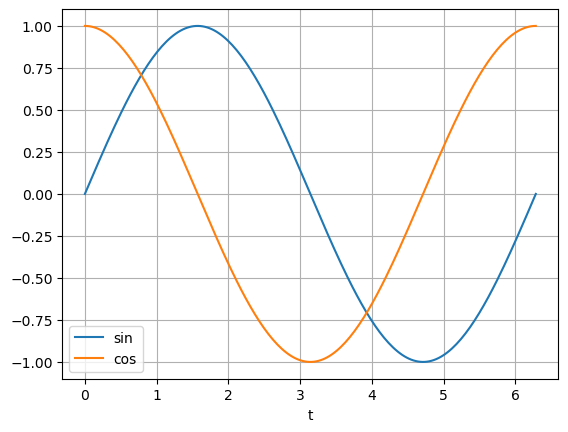

In [46]:
import matplotlib.pyplot as plt

t = np.linspace(0, 2*np.pi, 200)
plt.plot(t, np.sin(t), label="sin")
plt.plot(t, np.cos(t), label="cos")
plt.xlabel("t"); plt.legend(); plt.grid(True)
plt.show()

**Scripts with arguments.** \
The library `argparse` reads command-line arguments;\
The command `if __name__ == "__main__":` runs code only when the file is executed, not when imported.


In [47]:
%%writefile $MYPATH/TestScript/testscript.py
import argparse
from pathlib import Path

if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Find a word")
    parser.add_argument("word", nargs="?", default="Bash")
    args = parser.parse_args()

    Path("words.txt").write_text("Linux Bash Scripting\n")
    Path("numbers.txt").write_text("101 202 303\n")
    print("Files created!")
    variablePy = "Now I remember!"

    print("--------------------")
    for file in sorted(Path(".").glob("*.txt")):
        if file.is_file():
            text = file.read_text()
            if args.word in text:
                print(f"Word {args.word} found in {file}")
                print(text, end="")
            else:
                print(f"Word {args.word} NOT found in {file}")
        print("--------------------")
    print("Script executed!")

Overwriting /home/dario/Projects/CollabCoding/TestScript/testscript.py


We can then execute the python script as:

In [48]:
%%bash
cd TestScript/
python testscript.py Test
echo $variablePy

bash: line 1: cd: TestScript/: No such file or directory


Files created!
--------------------
Word Test NOT found in numbers.txt
--------------------
Word Test NOT found in text.txt
--------------------
Word Test NOT found in words.txt
--------------------
Script executed!



In notebooks, the command %run for python shares memory with the current shell:

In [49]:
%cd TestScript/
%run testscript.py
%cd ..
!echo $variablePy

[Errno 2] No such file or directory: 'TestScript/'
/home/dario/Projects/CollabCoding/TestScript
Files created!
--------------------
Word Bash NOT found in numbers.txt
--------------------
Word Bash NOT found in text.txt
--------------------
Word Bash found in words.txt
Linux Bash Scripting
--------------------
Script executed!
/home/dario/Projects/CollabCoding
Now I remember!


We can now remember the variable: run scripts this way to inherit the subprocesses variables!



---



# Machine Learning

**Machine learning** (ML) builds models whose parameters are *learned from data* instead of being written by hand.

- **Supervised**: inputs `X` with known targets `y` (regression, classification).
- **Unsupervised**: only `X`, the model finds structure (clustering, dimensionality reduction, autoencoders).

Basic workflow: prepare data → split into train/test → define model and loss → train → evaluate on unseen data.\
Overfitting (good on train, bad on test) is the main enemy, hence the split and the *validation loss*.

Libraries used here: `scikit-learn` (classic ML) and `keras` (neural networks, on top of TensorFlow). Install them in your active environment first:

In [50]:
#!pip install scikit-learn tensorflow

**A first supervised example** with scikit-learn: classify iris flowers.

In [51]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X_iris, y_iris = load_iris(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X_iris, y_iris, test_size=0.3, random_state=42)

clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(Xtr, ytr)                                   # training
print("test accuracy:", accuracy_score(yte, clf.predict(Xte)))

test accuracy: 1.0


**Neural networks and autoencoders**

A neural network is a stack of `Dense` layers: each computes `activation(W·x + b)`, and training adjusts `W, b` by gradient descent to minimise a **loss** function.

An **autoencoder** is trained to reproduce its own input through a narrow bottleneck:

`input → encoder → latent code → decoder → reconstruction`

The latent code is a compressed representation of the data. Here we compress points on a noisy circle (2 numbers) into a single number, which should learn the angle.

*1. Data*: a ring of radius ~1 with small noise, split in train and validation sets.

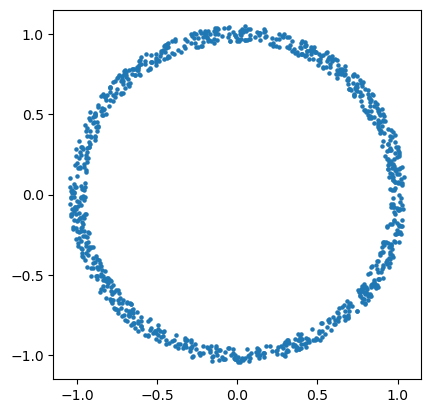

In [52]:
from math import pi

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split as test_split

np.random.seed(42)                      # reproducibility
N = 1000

theta = np.random.random(N) * 2 * pi
radius = 0.95 + np.random.random(N) * 0.1

x = radius * np.cos(theta)
y = radius * np.sin(theta)
X = np.stack((x, y), axis=1)            # shape (N, 2)

# autoencoder: the target is the input itself
X_train, X_test, y_train, y_test = test_split(X, X, test_size=0.5, random_state=42)

plt.figure('Data')
plt.scatter(x, y, s=5)
plt.gca().set_aspect('equal')
plt.show()

*2. Model*: 2 → 300 → 300 → **1** → 300 → 300 → 2. The single sigmoid neuron is the bottleneck.

In [53]:
from keras.models import Model
from keras.layers import Input, Dense

inputs = Input(shape=(2,))
hidden = Dense(300, activation='relu')(inputs)
hidden = Dense(300, activation='relu')(hidden)
latent = Dense(1, activation='sigmoid')(hidden)
dec1 = Dense(300, activation='relu')
dec2 = Dense(300, activation='relu')
dec3 = Dense(2, activation='linear')
outputs = dec3(dec2(dec1(latent)))

model = Model(inputs=inputs, outputs=outputs, name='autoencoder')
model.compile(optimizer='adam', loss='MSE')
model.summary()

2026-10-23 14:45:36.467906: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │           900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 300)            │        90,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           301 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │           600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 300)            │        90,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │           602 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,003 (714.86 KB)

 Trainable params: 183,003 (714.86 KB)

 Non-trainable params: 0 (0.00 B)

*3. Training* with two useful callbacks: stop when the validation loss stops improving, and halve the learning rate on plateaus.

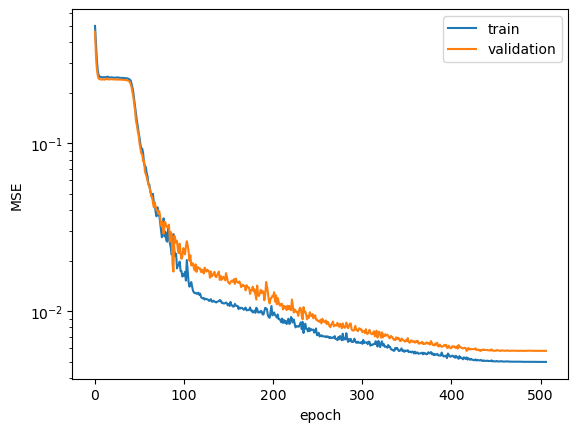

In [54]:
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

history = model.fit(X_train, y_train,
          validation_data=(X_test, y_test),
          epochs=1000, verbose=0,
          callbacks=[
              EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True),
              ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15)
          ])

plt.figure('Training')
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.yscale('log'); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend()
plt.show()

*4. Encoder and decoder.* The encoder reuses the trained layers up to the latent code. For the decoder we need a **new `Input`** of shape `(1,)` and the *same* decoder layers (a `Model` cannot start from an intermediate tensor).

In [55]:
encoder = Model(inputs=inputs, outputs=latent, name='encoder')

latent_in = Input(shape=(1,))
decoder = Model(inputs=latent_in, outputs=dec3(dec2(dec1(latent_in))), name='decoder')

encoder.summary()
decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │           900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 300)            │        90,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           301 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,501 (357.43 KB)

 Trainable params: 91,501 (357.43 KB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │           600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 300)            │        90,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │           602 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,502 (357.43 KB)

 Trainable params: 91,502 (357.43 KB)

 Non-trainable params: 0 (0.00 B)

*5. Use it*: generate new points by decoding random latent values (`predict` needs shape `(N, 1)`), and check what the latent code means.

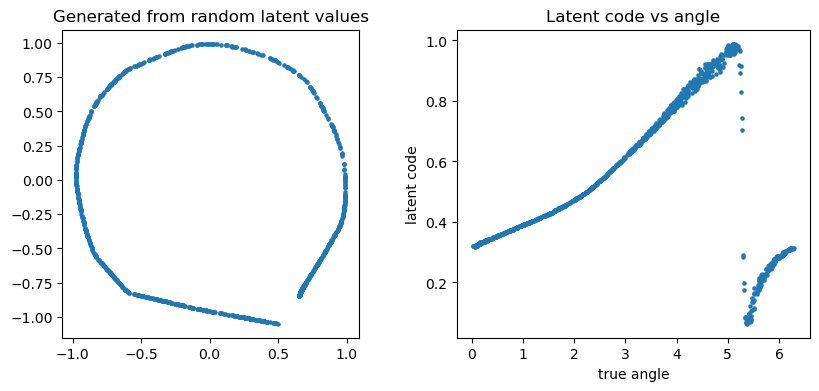

In [56]:
pred = decoder.predict(np.random.random((N, 1)), verbose=0)
code_1d = encoder.predict(X, verbose=0).ravel()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(pred[:, 0], pred[:, 1], s=5)
ax[0].set_title("Generated from random latent values"); ax[0].set_aspect('equal')
ax[1].scatter(theta, code_1d, s=5)
ax[1].set_xlabel("true angle"); ax[1].set_ylabel("latent code")
ax[1].set_title("Latent code vs angle")
plt.show()

**Other useful things**

- Use fewer neurons for quick tests (e.g. 32 instead of 300): training is much faster.
- `model.save("autoencoder.keras")` and `keras.models.load_model(...)` store and reload a trained model.
- Always compare train and validation loss: a growing gap means overfitting (use more data, `Dropout`, a smaller model, early stopping).
- Neural networks train better with inputs of order 1: rescale data (e.g. `StandardScaler`) when needed.
- On Linux, GPUs are used automatically if the CUDA-enabled TensorFlow is installed in the environment.